# SE374.R11 - Topic 6: Weakly-Supervised Segmentation for WSI (LowMagWSS)
## Thin Google Drive Runner v2: `NVIDIA T4 GPU (16GB VRAM) - Full Official Benchmark (4,986 Patches)`

* **Mon hoc:** SE374.R11 - Phat trien phan mem xu ly anh y khoa (UIT - DHQG-HCM)
* **Giang vien huong dan:** TS. Nguyen Vinh Tiep
* **Nhom thuc hien:** Nhom 5 - Nguyễn Trọng Khôi (23520790) & Lê Nguyễn Thành Tài (23521374)
* **Kien truc Notebook:** **Thin Drive Runner v2** - Toan bo ma nguon mo hinh (`WSSSTissueStage1NetCAM`, `DeepLabV3Plus`), bo tai du lieu (`downloader.py`), trinh suy luan 7 phuong phap SOTA (`MultiMethodWSSSEngineV2`) va trinh xuat bieu do 300-DPI (`visualizer.py`) duoc dong goi trong thu muc code tren Google Drive (`src/`). Moi o code trong notebook nay chi giu vai tro dieu phoi gon nhe (`<= 25` dong/o).
* **Cau hinh phan cung:** Cau hinh danh rieng cho **Google Colab Free / Pro NVIDIA Tesla T4 (16GB GDDR6)** chay **Toan bo 4,986 anh kiem dinh (Full Official BCSS-WSSS Benchmark)**.
* **Thoi gian chay du kien:** ~25 - 35 phut tren NVIDIA T4 (FP16 Mixed Precision, 7 SOTA Methods x 4,986 anh)

### 7 Phuong Phap SOTA & Ablation Duoc Doi Soat Dong Thoi (`M1` -> `M7`)
1. `M1_Baseline_SingleScale`: Stage-2 DeepLabV3+ ResNet-101 Single-Scale Baseline (`Is_GM=False`)
2. `M2_MultiView_D4_TTA`: Stage-1 ResNet38d Net_CAM Classification Gate (`y_cls > 0.1`) + Dihedral D4 TTA
3. `M3_LongTail_Prior_Calibration`: Stage-1 CGM + Cross-Stage CAM Fusion + Long-Tail Prior Calibration
4. `M4_Spatial_Bilateral_Refinement`: Stage-1 CGM + D4 TTA + PistoSeg/ARML Bilateral Spatial Refinement
5. `M5_Proposed_SOTA_Ensemble`: Proposed V1 Ensemble (CGM + CAM Fusion + D8 TTA + Prior Calib + Spatial Refinement + Glass Guard)
6. `M6_MultiScale_Pyramid_D4_Ensemble`: Multi-Scale Pyramid (`0.75x, 1.0x, 1.25x`) Inverse-Entropy D4 + Adaptive Soft-Gating
7. `M7_Proposed_Ultra_SOTA_Curriculum`: **Proposed V2 Ultra-SOTA Curriculum (Multi-Scale D4 + Adaptive Soft-Gate + Entropy CAM Fusion + H&E Beer-Lambert Optical Density Calib + Multi-Stride Edge-Guided Refinement)**

---
## Buoc 1: Mount Google Drive, Nap Thu Muc Code (`src/`) & Khoi Tao Moi Truong GPU
O code duoi day ket noi Google Drive, tu dong tim thu muc code `SE374_WSSS_Drive_Code` (hoac giai nen tu file `SE374_WSSS_Drive_Code.zip` tren Drive / dung repo hien tai), them vao `sys.path` va goi `set_reproducible_seed()`.

In [1]:
import os, sys, zipfile
from pathlib import Path

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)

MYDRIVE = Path("/content/drive/MyDrive")
DRIVE_ZIPS = [MYDRIVE / "SE374_WSSS_Project/SE374_WSSS_Drive_Code.zip", MYDRIVE / "SE374_WSSS_Drive_Code.zip", Path("/content/SE374_WSSS_Drive_Code.zip")]
if MYDRIVE.is_dir(): DRIVE_ZIPS += sorted(MYDRIVE.glob("*/SE374_WSSS_Drive_Code.zip")) + sorted(MYDRIVE.glob("*/*/SE374_WSSS_Drive_Code.zip"))
for zp in DRIVE_ZIPS:
    if zp.is_file() and not Path("/content/SE374_WSSS_Drive_Code/src").is_dir():
        with zipfile.ZipFile(zp, "r") as zf: zf.extractall("/content/SE374_WSSS_Drive_Code")
        break

CANDIDATES = [MYDRIVE / "SE374_WSSS_Project/SE374_WSSS_Drive_Code", MYDRIVE / "SE374_WSSS_Drive_Code", MYDRIVE / "SE374_WSSS_Project",
              MYDRIVE / "SE374_WSSS_Code", MYDRIVE / "Y_KHOA", Path("/content/SE374_WSSS_Drive_Code"), Path("/content/SE374_WSSS_Drive_Code/SE374_WSSS_Drive_Code"), Path.cwd(), Path.cwd().parent]
if MYDRIVE.is_dir(): CANDIDATES += sorted(MYDRIVE.glob("*/SE374_WSSS_Drive_Code"))
CODE_ROOT = str(next((p.resolve() for p in CANDIDATES if (p / "src" / "pipeline").is_dir()), Path.cwd().resolve()))
if CODE_ROOT in sys.path: sys.path.remove(CODE_ROOT)
sys.path.insert(0, CODE_ROOT)

from src.pipeline.colab_runner import set_reproducible_seed
ENV_INFO = set_reproducible_seed(seed=42, verbose=True)
print(f"[READY] CODE_ROOT = {CODE_ROOT}")

Mounted at /content/drive
PyTorch Version: 2.10.0+cu128
CUDA Available : True
GPU Model      : Tesla T4 (14.74 GB VRAM)
CUDA Devices   : 1
[READY] CODE_ROOT = /content/SE374_WSSS_Drive_Code

---
## Buoc 2: Thiet Lap Cau Hinh Phan Cung Chuyen Biet (`T4` - `T4_Full4986`)
Cau hinh duoc toi uu hoa cho **T4 GPU** voi che do **FP16 (torch.float16)** va `SANITY_MODE = False`.

In [2]:
import torch

MODE_TAG = "T4_Full4986"
SANITY_MODE = False
MAX_SANITY_SAMPLES = 150
MIN_SANITY_PATIENTS = 5
USE_AMP = True
AMP_DTYPE = torch.float16
USE_TF32 = False
PROGRESS_INTERVAL = 250
WORK_ROOT = Path("/content" if "google.colab" in sys.modules else "./se374_wsss_work")
DRIVE_CACHE_DIR = Path("/content/drive/MyDrive/SE374_WSSS_Cache") if os.path.isdir("/content/drive/MyDrive") else None
DRIVE_EXPORT_DIR = (DRIVE_CACHE_DIR / f"outputs_{MODE_TAG}") if DRIVE_CACHE_DIR else None

if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = USE_TF32
    torch.backends.cudnn.allow_tf32 = USE_TF32
print(f"[CONFIG] Mode={MODE_TAG} | Sanity={SANITY_MODE} | AMP={AMP_DTYPE} | TF32={USE_TF32}")

[CONFIG] Mode=T4_Full4986 | Sanity=False | AMP=torch.float16 | TF32=False

---
## Buoc 3: Tai Tu Dong Du Lieu BCSS-WSSS & Trong So Stage-1 / Stage-2 (Co Cache Google Drive)
Cac ham `ensure_bcss_dataset()`, `select_patient_files()` va `ensure_checkpoints()` tu dong kiem tra cache tren Google Drive, tai du lieu `BCSS-WSSS.zip` + trong so `Stage-1 ResNet38d` + `Stage-2 DeepLabV3+` va tach tap kiem dinh theo Patient ID (INVARIANT-08).

In [3]:
from src.pipeline.colab_runner import ensure_bcss_dataset, ensure_checkpoints, select_patient_files

DATA_ROOT, TEST_IMG_DIR, TEST_MASK_DIR = ensure_bcss_dataset(
    data_root=WORK_ROOT / "BCSS-WSSS",
    zip_path=WORK_ROOT / "BCSS-WSSS.zip",
    extract_dir=WORK_ROOT,
    drive_cache_dir=DRIVE_CACHE_DIR,
)
ACTIVE_TEST_FILES, PATIENT_TO_FILES = select_patient_files(
    test_img_dir=TEST_IMG_DIR,
    sanity_mode=SANITY_MODE,
    max_sanity_samples=MAX_SANITY_SAMPLES,
    min_sanity_patients=MIN_SANITY_PATIENTS,
)
CKPT_PATHS = ensure_checkpoints(
    checkpoint_dir=WORK_ROOT / "checkpoints",
    drive_cache_dir=DRIVE_CACHE_DIR,
    require_stage2=True,
)
print(f"[ASSETS] Active patches: {len(ACTIVE_TEST_FILES)} across {len(PATIENT_TO_FILES)} TCGA patients")

[OK] Thư mục gốc dữ liệu: /content/BCSS-WSSS
[OK] Thư mục ảnh test   : /content/BCSS-WSSS/test/img
[OK] Thư mục mask test  : /content/BCSS-WSSS/test/mask
[OK] Tổng số ảnh test tìm thấy: 4986 ảnh | Tổng số mask: 4986 mask
--> Tổng số mảng ảnh test thực tế: 4986 ảnh
--> Tổng số bệnh nhân trong tập test: 23 bệnh nhân

[CHẾ ĐỘ FULL BENCHMARK]: Chạy toàn bộ 4986 mảng ảnh thật trên toàn bộ 23 bệnh nhân!
[OK] Checkpoint Stage 1 đã sẵn sàng tại: /content/checkpoints/stage1_checkpoint_trained_on_bcss.pth (401.14 MB)
[OK] Checkpoint Stage 2 đã sẵn sàng tại: /content/checkpoints/stage2_checkpoint_trained_on_bcss.pth (453.49 MB)
[ASSETS] Active patches: 4986 across 23 TCGA patients

---
## Buoc 4: Khoi Tao Mo Hinh `ResNet38d` + `DeepLabV3+` & Engine 7 Phuong Phap (`MultiMethodWSSSEngineV2`)
Nap trong so da huan luyen qua `load_wsss_models()` va khoi tao `MultiMethodWSSSEngineV2` ho tro day du 7 phuong phap tu `M1_Baseline_SingleScale` den `M7_Proposed_Ultra_SOTA_Curriculum`.

In [4]:
from src.pipeline.colab_runner import load_wsss_models
from src.models.wsss_inference_methods import MultiMethodWSSSEngineV2

MODEL_STAGE2, MODEL_STAGE1, DEVICE = load_wsss_models(
    stage2_ckpt=CKPT_PATHS["stage2"],
    stage1_ckpt=CKPT_PATHS["stage1"],
    device=ENV_INFO["device"],
)
WSSS_ENGINE = MultiMethodWSSSEngineV2(
    model_stage1=MODEL_STAGE1, use_amp=USE_AMP, amp_dtype=AMP_DTYPE,
)
print(f"[ENGINE] Initialized {len(WSSS_ENGINE.METHOD_KEYS)} WSSS methods on {DEVICE} (AMP={USE_AMP}, dtype={AMP_DTYPE}):")
for m_key in WSSS_ENGINE.METHOD_KEYS:
    print(f"  - {m_key}: {WSSS_ENGINE.METHOD_NAMES_VI[m_key]}")

[OK] Thiết bị tính toán: cuda
--> Đang đọc checkpoint Stage 2: stage2_checkpoint_trained_on_bcss.pth
--> Phát hiện số lớp đầu ra từ checkpoint: 4 phân lớp
[OK] Nạp trọng số Stage 2 thành công (Missing: 0, Unexpected: 0)
--> Đang đọc checkpoint Stage 1: stage1_checkpoint_trained_on_bcss.pth
[OK] Nạp trọng số Stage 1 thành công (Missing: 0, Unexpected: 0)
[ENGINE] Initialized 7 WSSS methods on cuda (AMP=True, dtype=torch.float16):
  - M1_Baseline_SingleScale: M1: Baseline WSSS-Tissue (Single-Scale)
  - M2_MultiView_D4_TTA: M2: + Đa Góc Nhìn Dihedral TTA & Stage-1 CGM
  - M3_LongTail_Prior_Calibration: M3: + Kết Hợp CAM Đa Giai Đoạn & Hiệu Chỉnh Đuôi Dài
  - M4_Spatial_Bilateral_Refinement: M4: + Tinh Chỉnh Biên Không Gian & Triệt Tiêu Đảo Nhiễu (ARML/PistoSeg)
  - M5_Proposed_SOTA_Ensemble: M5: Phương Pháp Đề Xuất Toàn Diện (Full SOTA Pipeline)
  - M6_MultiScale_Pyramid_D4_Ensemble: M6: + Kim Tự Tháp Đa Tỷ Lệ D4 (Entropy-Weighted) & Cổng Mềm Stage-1
  - M7_Proposed_Ultra_SOTA_Curriculum:

---
## Buoc 5: Chay Thuc Nghiem Doi Soat 7 Phuong Phap (`M1` -> `M7`) & Kiem Dinh Thong Ke Wilcoxon
Ham `run_streaming_evaluation()` tich luy ma tran nham lan toan cuc tren toan bo tap kiem dinh cho tung phuong phap trong 7 phuong phap (`M1`..`M7`), tinh chinh xac `4-class mIoU (%)`, `5-class mIoU (%)`, `Macro Dice (%)`, `IoU` tung lop (`TUM`, `STR`, `LYM`, `NEC`) va kiem dinh Wilcoxon signed-rank test.

In [5]:
import pandas as pd
from IPython.display import display
from src.pipeline.colab_runner import run_streaming_evaluation

EVAL_OUT = run_streaming_evaluation(
    active_test_files=ACTIVE_TEST_FILES, test_mask_dir=TEST_MASK_DIR, model=MODEL_STAGE2,
    model_stage1=MODEL_STAGE1, device=DEVICE, wsss_engine=WSSS_ENGINE,
    include_v2=True, use_amp=USE_AMP, amp_dtype=AMP_DTYPE,
    progress_interval=PROGRESS_INTERVAL, verbose=True,
)
SUMMARY_ROWS = [
    {"Method": k, "mIoU_4cls (%)": round(v["mIoU_4cls"], 2), "mDice_4cls (%)": round(v["mDice_4cls"], 2),
     "mIoU_5cls (%)": round(v["mIoU_5cls"], 2), "TUM_IoU (%)": round(v["per_class_iou"]["TUM"], 2),
     "STR_IoU (%)": round(v["per_class_iou"]["STR"], 2), "LYM_IoU (%)": round(v["per_class_iou"]["LYM"], 2),
     "NEC_IoU (%)": round(v["per_class_iou"]["NEC"], 2)}
    for k, v in EVAL_OUT["all_methods_metrics"].items()
]
SUMMARY_DF = pd.DataFrame(SUMMARY_ROWS)
display(SUMMARY_DF)

--> Bắt đầu thực thi đánh giá so sánh 7 Phương Pháp Nghiên Cứu (Ablation & Multi-Method Benchmark) trên 4986 mảng ảnh bệnh nhân thật...
--> Tiến trình chạy trên cuda bằng PyTorch DeepLabV3+ ResNet-101 thực thụ...
  * Tiến trình: [ 250/4986] mảng ảnh đã được đánh giá qua 7 phương pháp...
  * Tiến trình: [ 500/4986] mảng ảnh đã được đánh giá qua 7 phương pháp...
  * Tiến trình: [ 750/4986] mảng ảnh đã được đánh giá qua 7 phương pháp...
  * Tiến trình: [1000/4986] mảng ảnh đã được đánh giá qua 7 phương pháp...
  * Tiến trình: [1250/4986] mảng ảnh đã được đánh giá qua 7 phương pháp...
  * Tiến trình: [1500/4986] mảng ảnh đã được đánh giá qua 7 phương pháp...
  * Tiến trình: [1750/4986] mảng ảnh đã được đánh giá qua 7 phương pháp...
  * Tiến trình: [2000/4986] mảng ảnh đã được đánh giá qua 7 phương pháp...
  * Tiến trình: [2250/4986] mảng ảnh đã được đánh giá qua 7 phương pháp...
  * Tiến trình: [2500/4986] mảng ảnh đã được đánh giá qua 7 phương pháp...
  * Tiến trình: [2750/4986] mảng ảnh 

                                Method  mIoU_4cls (%)  mDice_4cls (%)  mIoU_5cls (%)  TUM_IoU (%)  STR_IoU (%)  LYM_IoU (%)  NEC_IoU (%)
0  M1_Baseline_SingleScale                    69.35         81.69        75.47       78.46       73.32       60.00       65.62
1  M2_MultiView_D4_TTA                        70.30         82.37        76.23       79.08       73.88       60.75       67.51
2  M3_LongTail_Prior_Calibration              70.50         82.51        76.38       79.23       73.78       61.31       67.66
3  M4_Spatial_Bilateral_Refinement            70.32         82.38        76.24       79.09       73.89       60.77       67.53
4  M5_Proposed_SOTA_Ensemble                  70.51         82.52        76.39       79.24       73.79       61.33       67.67
5  M6_MultiScale_Pyramid_D4_Ensemble          70.53         82.54        76.41       79.37       73.82       61.33       67.61
6  M7_Proposed_Ultra_SOTA_Curriculum          70.44         82.47        76.34       79.25       73.8

---
## Buoc 6: Truc Quan Hoa 3 Bieu Do Khoa Hoc Chuẩn 300-DPI (Clinical Comparison, Confusion Matrix & Ablation Chart)
Su dung `render_clinical_comparison_figure()`, `render_confusion_matrix_heatmap()` va `render_ablation_bar_chart()` tu `src.pipeline.colab_runner` de xuat bo hinh anh 300-DPI phuc vu bao cao SE374.R11.

[OK] Đã lưu ảnh so sánh lâm sàng 300 DPI tại: /content/SE374_Colab_Results_DeepLabV3Plus_T4_Full4986_20261020_205548/clinical_segmentation_comparison.png
[OK] Đã lưu biểu đồ ma trận nhầm lẫn 300 DPI tại: /content/SE374_Colab_Results_DeepLabV3Plus_T4_Full4986_20261020_205548/confusion_matrix_5x5.png
[OK] Đã lưu biểu đồ so sánh Ablation Study 300 DPI tại: /content/SE374_Colab_Results_DeepLabV3Plus_T4_Full4986_20261020_205548/ablation_methods_comparison.png

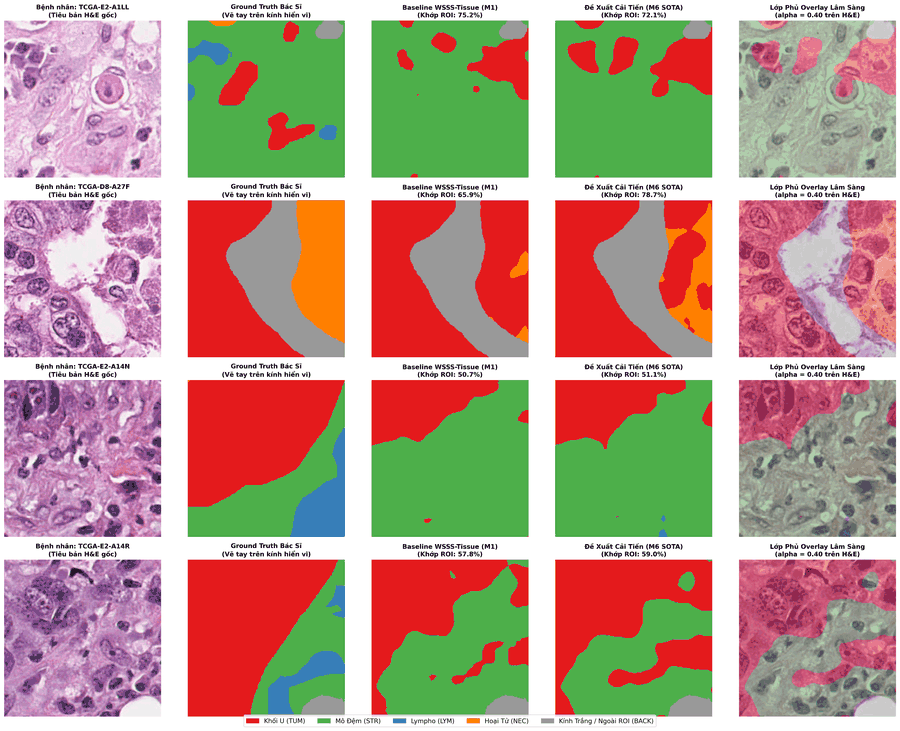

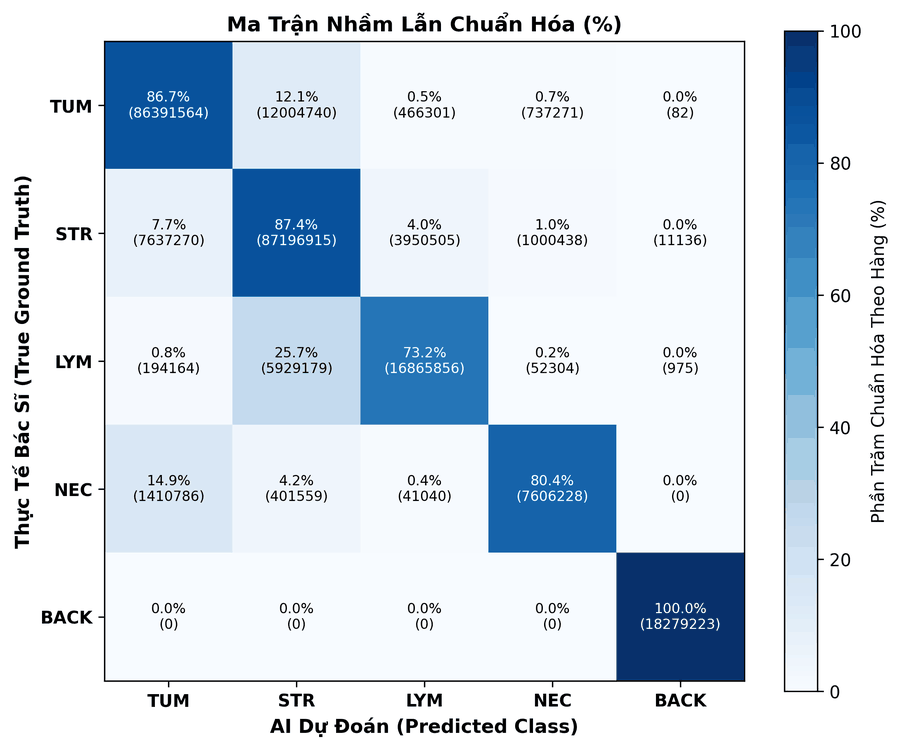

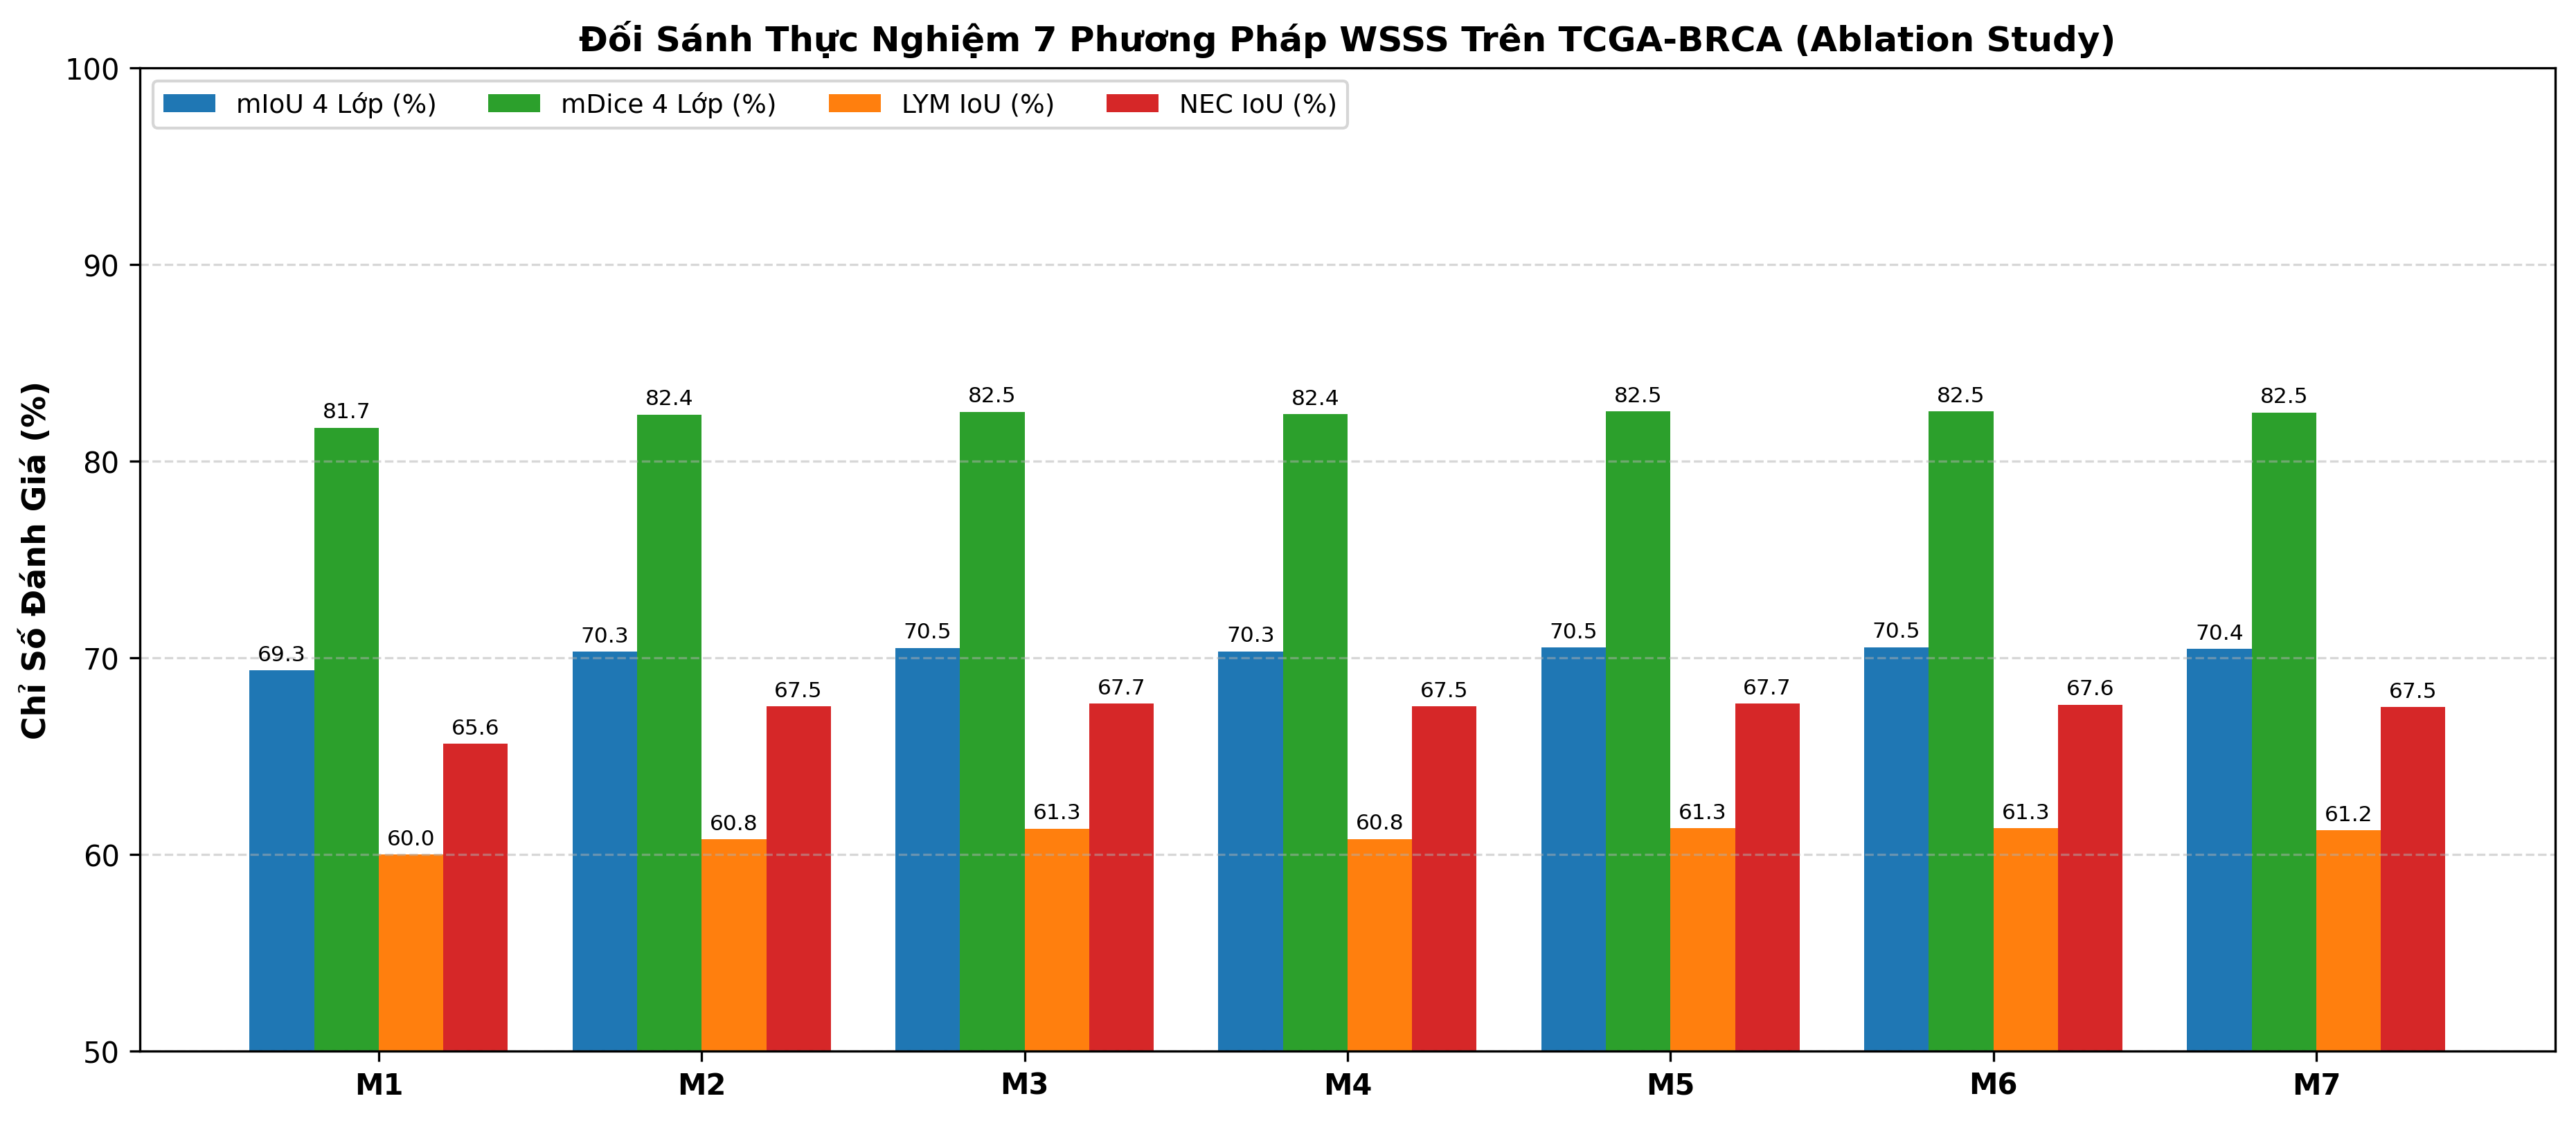

In [6]:
import datetime
from src.pipeline.colab_runner import CLASS_CODES, render_ablation_bar_chart, render_clinical_comparison_figure, render_confusion_matrix_heatmap

RUN_FOLDER_NAME = f"SE374_Colab_Results_DeepLabV3Plus_{MODE_TAG}_{datetime.datetime.now().strftime('%Y%m%d_%H%M%S')}"
OUTPUT_DIR = WORK_ROOT / RUN_FOLDER_NAME
LEGACY_DIR = WORK_ROOT / "SE374_Colab_Results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

_, VIS_IMG_PATH = render_clinical_comparison_figure(
    active_test_files=ACTIVE_TEST_FILES, test_mask_dir=TEST_MASK_DIR, model=MODEL_STAGE2, wsss_engine=WSSS_ENGINE,
    best_method_key=EVAL_OUT["best_method_key"], model_stage1=MODEL_STAGE1, device=DEVICE,
    output_dir=OUTPUT_DIR, legacy_dir=LEGACY_DIR, sample_count=min(4, len(ACTIVE_TEST_FILES)), show_plots=True,
)
_, CM_IMG_PATH = render_confusion_matrix_heatmap(
    confusion_matrix=EVAL_OUT["metrics"]["confusion_matrix"], class_codes=CLASS_CODES,
    output_dir=OUTPUT_DIR, legacy_dir=LEGACY_DIR, show_plots=True,
)
_, BAR_IMG_PATH = render_ablation_bar_chart(
    all_methods_metrics=EVAL_OUT["all_methods_metrics"], method_keys=list(EVAL_OUT["all_methods_metrics"].keys()),
    output_dir=OUTPUT_DIR, legacy_dir=LEGACY_DIR, show_plots=True,
)

---
## Buoc 7: Xuat Bao Cao JSON/CSV/Markdown & Dong Bo File ZIP Ve Google Drive
Ham `export_evaluation_artifacts()` va `package_and_download_results()` luu day du bang ket qua (`ablation_study_metrics.csv`, `per_class_metrics.csv`, `COLAB_EVALUATION_REPORT.json`, `COLAB_EVALUATION_REPORT.md`), nen thanh file `.zip` va sao luu tu dong vao Google Drive.

In [7]:
from src.pipeline.colab_runner import export_evaluation_artifacts, package_and_download_results

EXPORTED_FILES = export_evaluation_artifacts(
    output_dir=OUTPUT_DIR,
    run_folder_name=RUN_FOLDER_NAME,
    mode_tag=MODE_TAG,
    sanity_mode=SANITY_MODE,
    evaluated_count=EVAL_OUT["evaluated_count"],
    metrics=EVAL_OUT["metrics"],
    all_methods_metrics=EVAL_OUT["all_methods_metrics"],
    method_keys=list(EVAL_OUT["all_methods_metrics"].keys()),
    method_names_vi=WSSS_ENGINE.METHOD_NAMES_VI,
    statistical_tests=EVAL_OUT["statistical_tests"],
    gpu_name=ENV_INFO["gpu_name"],
    legacy_dir=LEGACY_DIR,
)
ZIP_FILE_PATH = package_and_download_results(
    output_dir=OUTPUT_DIR, drive_export_dir=DRIVE_EXPORT_DIR, trigger_browser_download=("google.colab" in sys.modules)
)
print(f"[EXPORT] Archive ready: {ZIP_FILE_PATH}")

[OK] Đã lưu báo cáo JSON: /content/SE374_Colab_Results_DeepLabV3Plus_T4_Full4986_20261020_205548/COLAB_EVALUATION_REPORT.json
[OK] Đã lưu bảng CSV Ablation: /content/SE374_Colab_Results_DeepLabV3Plus_T4_Full4986_20261020_205548/ablation_study_metrics.csv
[OK] Đã lưu bảng CSV từng lớp: /content/SE374_Colab_Results_DeepLabV3Plus_T4_Full4986_20261020_205548/per_class_metrics.csv
[OK] Đã lưu báo cáo Markdown: /content/SE374_Colab_Results_DeepLabV3Plus_T4_Full4986_20261020_205548/COLAB_EVALUATION_REPORT.md
[OK] Đã đóng gói thành công vào: /content/SE374_Colab_Results_DeepLabV3Plus_T4_Full4986_20261020_205548.zip
--> Đang kích hoạt trình duyệt tự động tải về tệp: SE374_Colab_Results_DeepLabV3Plus_T4_Full4986_20261020_205548.zip...
[OK] Yêu cầu tải tệp đã được gửi thành công tới trình duyệt!
[EXPORT] Archive ready: /content/SE374_Colab_Results_DeepLabV3Plus_T4_Full4986_20261020_205548.zip

---
## Buoc 8: Kiem Thu Nhanh Tren Anh Patch Bat Ky (`inspect_custom_patch`)
Tien ich `inspect_custom_patch(patch_path)` cho phep truyen duong dan 1 anh patch H&E bat ky de chay dong thoi ca 7 phuong phap (`M1`..`M7`) va in thong ke ty le dien tich tung lop mo.

In [8]:
import numpy as np
from PIL import Image as PILImage
from torchvision import transforms

def inspect_custom_patch(patch_path: str) -> None:
    raw_pil = PILImage.open(patch_path).convert("RGB")
    raw_np = np.array(raw_pil)
    inp_t = transforms.ToTensor()(raw_pil).unsqueeze(0).to(DEVICE)
    preds = WSSS_ENGINE.predict_all_methods(MODEL_STAGE2, inp_t, raw_rgb=raw_np, model_stage1=MODEL_STAGE1)
    print(f"Patch: {Path(patch_path).name} | Shape: {raw_np.shape}")
    for m_key, pred_mask in preds.items():
        mask = WSSS_ENGINE.apply_pure_glass_guard(pred_mask, raw_np, background_class_idx=4)
        ratios = { idx: round(float((mask == idx).mean() * 100.0), 2) for idx in range(5) }
        print(f"  {m_key:<36} -> class % (TUM=0,STR=1,LYM=2,NEC=3,BG=4): {ratios}")

if len(ACTIVE_TEST_FILES) > 0:
    inspect_custom_patch(str(ACTIVE_TEST_FILES[0]))

Patch: TCGA-E2-A1LL-DX1_xmin20496_ymin36593_MPP-0.2500.png | Shape: (224, 224, 3)
  M1_Baseline_SingleScale              -> class % (TUM=0,STR=1,LYM=2,NEC=3,BG=4): {0: 19.63, 1: 77.98, 2: 0.0, 3: 0.0, 4: 2.39}
  M2_MultiView_D4_TTA                  -> class % (TUM=0,STR=1,LYM=2,NEC=3,BG=4): {0: 21.84, 1: 75.77, 2: 0.0, 3: 0.0, 4: 2.39}
  M3_LongTail_Prior_Calibration        -> class % (TUM=0,STR=1,LYM=2,NEC=3,BG=4): {0: 22.15, 1: 75.46, 2: 0.0, 3: 0.0, 4: 2.39}
  M4_Spatial_Bilateral_Refinement      -> class % (TUM=0,STR=1,LYM=2,NEC=3,BG=4): {0: 21.88, 1: 75.73, 2: 0.0, 3: 0.0, 4: 2.39}
  M5_Proposed_SOTA_Ensemble            -> class % (TUM=0,STR=1,LYM=2,NEC=3,BG=4): {0: 22.19, 1: 75.42, 2: 0.0, 3: 0.0, 4: 2.39}
  M6_MultiScale_Pyramid_D4_Ensemble    -> class % (TUM=0,STR=1,LYM=2,NEC=3,BG=4): {0: 23.02, 1: 74.59, 2: 0.0, 3: 0.0, 4: 2.39}
  M7_Proposed_Ultra_SOTA_Curriculum    -> class % (TUM=0,STR=1,LYM=2,NEC=3,BG=4): {0: 22.74, 1: 74.87, 2: 0.0, 3: 0.0, 4: 2.39}